## 1. Setup: imports, paths, settings and plot style

In [45]:
# Initial imports
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Get the parent directory 
project_root = Path().resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
# Import custom modules
import Scripts.sql_server_connect as sql
import Scripts.python_cleaning as clean

QUERIES_DIR = project_root / "Queries" / "SQL Business queries"
ASSETS_DIR = project_root / "Assets"
ASSETS_DIR.mkdir(exist_ok=True)

# Database settings
# Set OLIST_SERVER and OLIST_DATABASE as environment variables to override these defaults.
SERVER = os.getenv("OLIST_SERVER", r"localhost\SQLEXPRESS")
DATABASE = os.getenv("OLIST_DATABASE", "OlistDB")

# Column names returned by the SQL files (change here if you rename them in SQL)
CAT_NAME_COL = "category_name"
GMV_COL = "gross_merchandise_value"   
AOV_COL = "average_order_value"
ORDERS_COL = "order_count"

TARGET = "Health & Beauty"

# Colours
OLIST_COLORS = {
    "primary_blue": "#3951db",
    "dark_navy": "#131b31",
    "coral_orange": "#d45d37",
    "gold": "#dfa344",
    "sage_green": "#88a86a",
    "mauve": "#d2abc2",
}

# Plot style: set once, applies to every chart below
plt.rcParams.update({
    "figure.figsize": (15, 5),
    "figure.facecolor": "white",
    "font.size": 11,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.titlepad": 15,
    "axes.titlecolor": OLIST_COLORS["gold"],
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "xtick.labelsize": 11,
    "xtick.color": OLIST_COLORS["gold"],
    "ytick.color": OLIST_COLORS["gold"],
    "legend.frameon": False,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.transparent": True,
})



Part 1: Category Sales Analysis for period 06.2017-06.2018
Targeted Category: Health And Beauty

In [2]:
# Connecting to MSSQL Server database
print(project_root)
engine = sql.mssql_engine(SERVER, DATABASE)

C:\Dev\EdmondAnt\OLIST_SQL_Challenge


Loading General Category Information

In [3]:
print("Data returned from Microsoft SQL Server:")
df_category_revenue = sql.load_sql_to_df(str(QUERIES_DIR/"SQL Revenue by Category.sql"), engine)
df_category_revenue = clean.clean_category_names(df_category_revenue, CAT_NAME_COL, {"Health Beauty": "Health & Beauty"})


# Filter Health & Beauty Category
hb_row =  df_category_revenue[df_category_revenue[CAT_NAME_COL] == TARGET]
if hb_row.empty:
    raise ValueError(f"'{TARGET}' not found. Categories: {df_category_revenue[CAT_NAME_COL].tolist()[:10]}...")

df_category_revenue.head(5)

Data returned from Microsoft SQL Server:


,category_name,category_count,gross_merchandise_value,gross_order_value,gross_freight_cost
0,Watches Gifts,4816,928731.94,1009303.76,80571.82
1,Health & Beauty,7117,915675.02,1049522.67,133847.65
2,Bed Bath Table,8238,764200.49,915548.31,151347.82
3,Sports Leisure,6378,725880.66,848627.37,122746.71
4,Computers Accessories,5900,667198.15,779591.61,112393.46


Saved: C:\Dev\EdmondAnt\OLIST_SQL_Challenge\Assets\top10.png


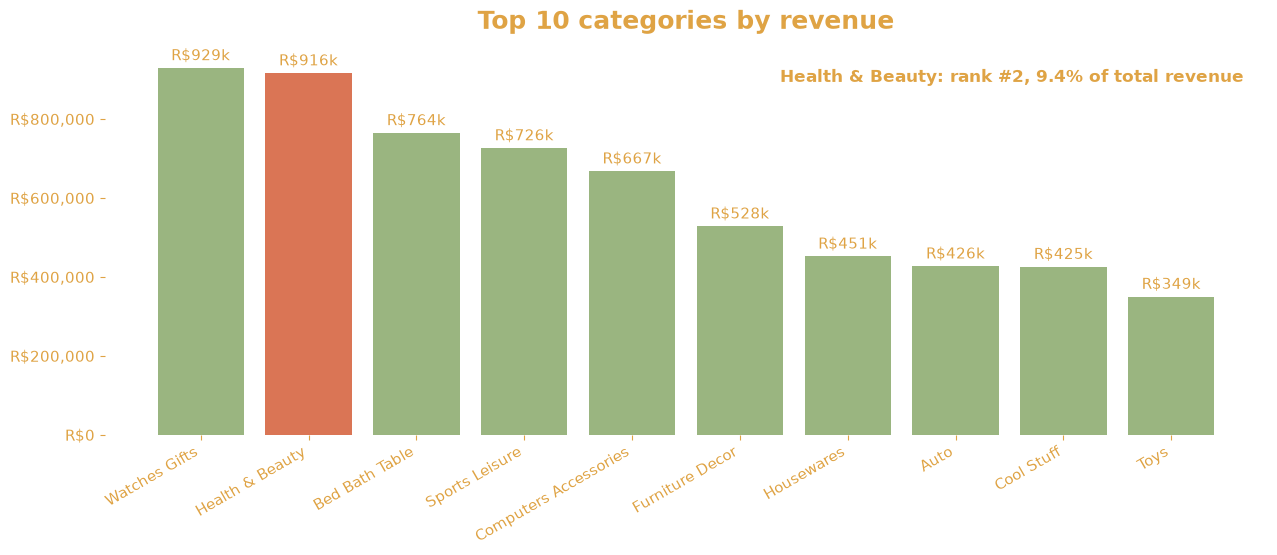

In [46]:
hb_rank = hb_row.index[0] + 1
hb_share = hb_row[GMV_COL].iloc[0] / df_category_revenue[GMV_COL].sum() * 100

top10 = df_category_revenue.head(10)
bar_colors = [
    OLIST_COLORS["coral_orange"] if name == TARGET else OLIST_COLORS["sage_green"]
    for name in top10[CAT_NAME_COL]
]

fig, ax = plt.subplots()
bars = ax.bar(top10[CAT_NAME_COL], top10[GMV_COL], color=bar_colors, alpha=0.85)
ax.bar_label(bars, labels=[f"R${v / 1000:,.0f}k" for v in top10[GMV_COL]], padding=3, color = OLIST_COLORS["gold"])
ax.yaxis.set_major_formatter("R${x:,.0f}")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_title("Top 10 categories by revenue")
ax.text(
    0.98, 0.95,
    f"{TARGET}: rank #{hb_rank}, {hb_share:.1f}% of total revenue",
    transform=ax.transAxes, ha="right", va="top",
    fontsize=12, fontweight="bold", color = OLIST_COLORS["gold"],
)

clean.save_chart(fig, ASSETS_DIR/"top10.png")
plt.show()

Health and Beaty revenue by month

Saved: C:\Dev\EdmondAnt\OLIST_SQL_Challenge\Assets\hb_monthly_revenue.png


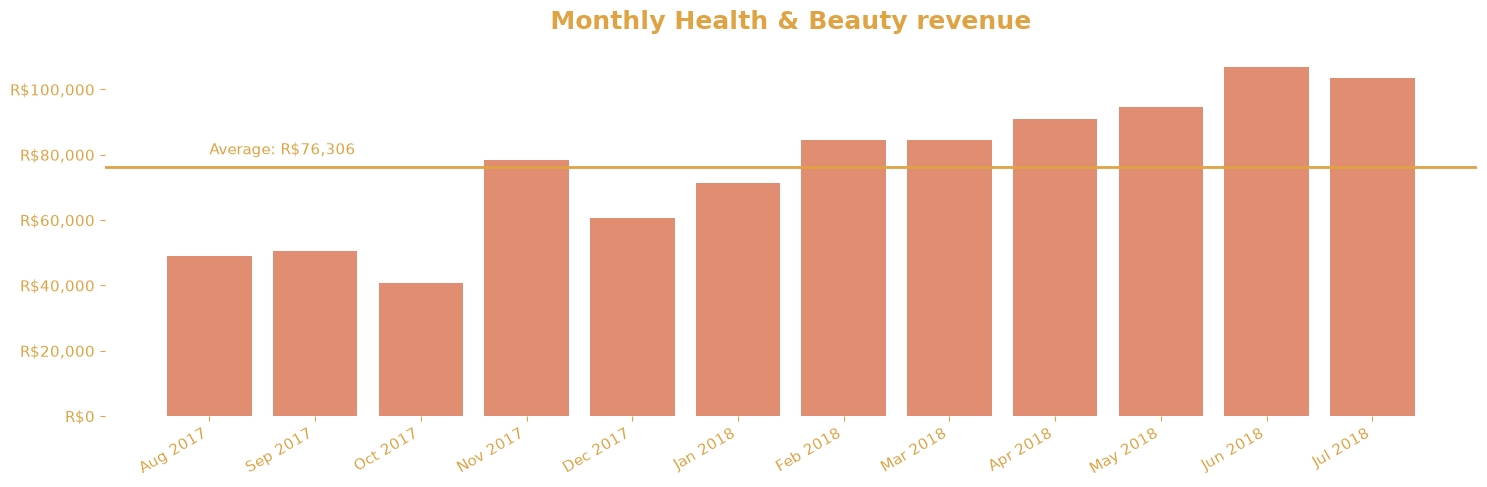

In [47]:
df_month = sql.load_sql_to_df(str(QUERIES_DIR/"SQL Revenue by Month.sql"), engine)
df_month = clean.clean_category_names(df_month, CAT_NAME_COL, {"Health Beauty": "Health & Beauty"})
df_hb = df_month[df_month[CAT_NAME_COL] == TARGET]


avg_revenue = df_hb[GMV_COL].mean()

fig, ax = plt.subplots()
x = clean.style_month_axis(ax, df_hb["order_period"])
ax.bar(x, df_hb[GMV_COL], color=OLIST_COLORS["coral_orange"], alpha=0.7)
ax.axhline(avg_revenue, color = OLIST_COLORS["gold"], linewidth=2)
ax.annotate(text=f"Average: R${avg_revenue:,.0f}", xy = (0, avg_revenue*1.05), color = OLIST_COLORS["gold"])
ax.yaxis.set_major_formatter("R${x:,.0f}")
ax.set_title(f"Monthly {TARGET} revenue")
fig.tight_layout()
clean.save_chart(fig, ASSETS_DIR/"hb_monthly_revenue.png")
plt.show()

We calculate revenue as number of orders x order price. If revenue grew during this period, it means that either number of order or average order price or both grew during the given period. Let's find out where the growth occured.

Saved: C:\Dev\EdmondAnt\OLIST_SQL_Challenge\Assets\hb_aov_and_orders.png


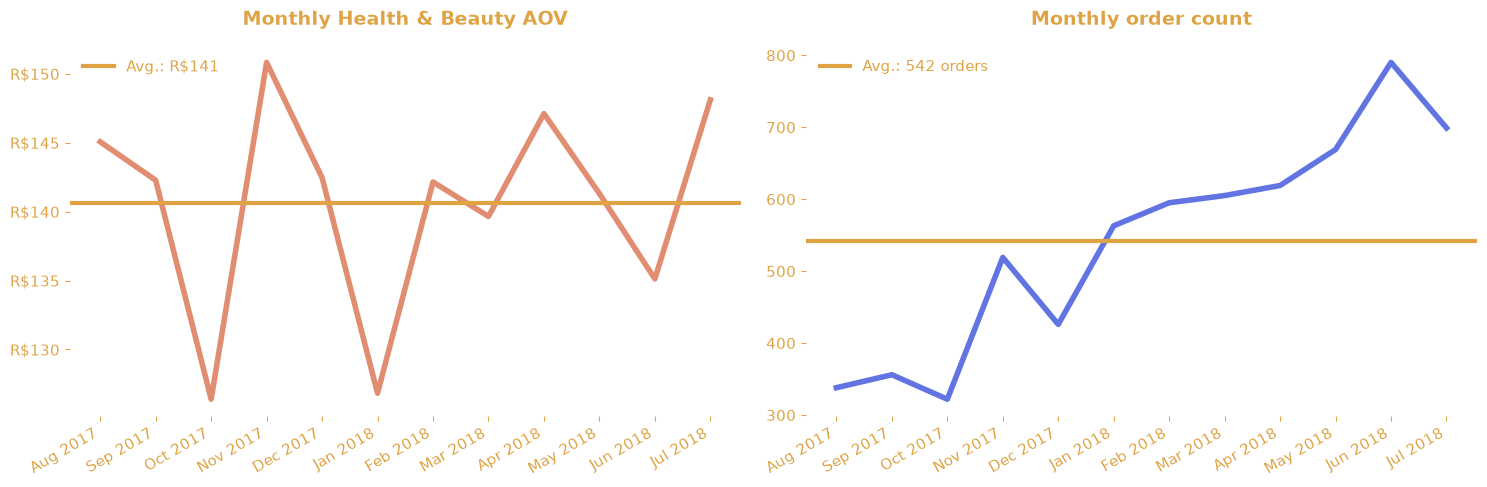

In [51]:
avg_aov = df_hb[AOV_COL].mean()
avg_orders = df_hb[ORDERS_COL].mean()

fig, (ax1, ax2) = plt.subplots(1, 2)

# Average order value
x = clean.style_month_axis(ax1, df_hb["order_period"])
ax1.plot(x, df_hb[AOV_COL], color=OLIST_COLORS["coral_orange"], linewidth=4, alpha=0.7)
ax1.axhline(avg_aov, color = OLIST_COLORS["gold"], linewidth=3, label=f"Avg.: R${avg_aov:,.0f}")
ax1.yaxis.set_major_formatter("R${x:,.0f}")
ax1.set_title(f"Monthly {TARGET} AOV", fontsize=14)
ax1.legend(loc="upper left", labelcolor = OLIST_COLORS["gold"])

# Number of orders (a count, so no currency symbol)
x = clean.style_month_axis(ax2, df_hb["order_period"])
ax2.plot(x, df_hb[ORDERS_COL], color=OLIST_COLORS["primary_blue"], linewidth=4, alpha=0.8)
ax2.axhline(avg_orders, color = OLIST_COLORS["gold"], linewidth=3, label=f"Avg.: {avg_orders:,.0f} orders",
            mec = OLIST_COLORS["gold"])
ax2.yaxis.set_major_formatter("{x:,.0f}")
ax2.set_title("Monthly order count", fontsize=14)
ax2.legend(loc="upper left", labelcolor = OLIST_COLORS["gold"])


fig.tight_layout()
clean.save_chart(fig, ASSETS_DIR/"hb_aov_and_orders.png")
plt.show()